In [1]:
!pip -q install torch numpy matplotlib
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Urządzenie: {DEVICE}')

Urządzenie: cpu


In [2]:
def gen_delayed(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        # Znaczniki losowane na pozycjach od 8 do L-1 (kroki od 9 do L)
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        # Dodaje wartości oddalone o 8 kroków w tył
        y[i, 0] = val[i, p - 8, 0].sum()
    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

# Weryfikacja dla jednego przykładu (L=20)
xx, yy = gen_delayed(1, 20)
poz_znacznikow = np.where(xx[0, :, 1].cpu().numpy() == 1)[0]
poz_wartosci = poz_znacznikow - 8
wartosci = xx[0, poz_wartosci, 0].cpu().numpy()
suma_prawdziwa = float(yy[0, 0])

print(f"Pozycje znaczników (0-based): {poz_znacznikow}")
print(f"Pozycje wskazywanych wartości (t-8): {poz_wartosci}")
print(f"Wskazywane wartości: {wartosci.round(3)}")
print(f"Obliczona suma (cel): {suma_prawdziwa:.4f}")

Pozycje znaczników (0-based): [12 17]
Pozycje wskazywanych wartości (t-8): [4 9]
Wskazywane wartości: [0.424 0.383]
Obliczona suma (cel): 0.8071


In [3]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class ConvNet(nn.Module):
    def __init__(self, ch=64, dilations=[1, 2, 4]):
        super().__init__()
        layers = []
        in_channels = 2
        # Dynamiczne budowanie warstw splotowych z odpowiednim paddingiem (k=3)
        for d in dilations:
            layers.append(nn.Conv1d(in_channels, ch, 3, padding=d, dilation=d))
            layers.append(nn.ReLU())
            in_channels = ch
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def licz_parametry(m):
    return sum(p.numel() for p in m.parameters())

In [4]:
def trenuj_fixed(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Lf = nn.MSELoss()
    N = Xtr.shape[0]

    t0 = time.time()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            Lf(model(Xtr[idx]), Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    czas = time.time() - t0

    model.eval()
    with torch.no_grad():
        mse = Lf(model(Xte), Yte).item()
    return mse, czas, model

In [5]:
N_train, N_test = 4000, 800
epoki = 30
wyniki = {}
model_do_analizy = None
dane_testowe_analiza = None

for L in [50, 100]:
    print(f"ZESTAWIENIE DLA L={L}")
    Xtr, Ytr = gen_delayed(N_train, L)
    Xte, Yte = gen_delayed(N_test, L)

    mean_y = Ytr.mean().item()
    baseline_mse = ((Yte.cpu().numpy() - mean_y)**2).mean()
    print(f"BASELINE (Predykcja stała = {mean_y:.3f}): Test MSE = {baseline_mse:.4f}\n")

    modele = {
        'SimpleRNN (h=32)': RNNNet('RNN', hidden=32),
        'LSTM (h=32)': RNNNet('LSTM', hidden=32),
        'GRU (h=32)': RNNNet('GRU', hidden=32),
        'Conv1D (d=[1,2,4])': ConvNet(ch=64, dilations=[1, 2, 4])
    }

    # Dodatkowe warianty
    if L == 100:
        modele['SimpleRNN (h=64)'] = RNNNet('RNN', hidden=64)
        modele['Conv1D (d=[1,1,1])'] = ConvNet(ch=64, dilations=[1, 1, 1])

    wyniki[L] = {}
    for nazwa, m in modele.items():
        mse, czas, trained_model = trenuj_fixed(m, Xtr, Ytr, Xte, Yte, epoki=epoki)
        wyniki[L][nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
        print(f"{nazwa:20s} | MSE: {mse:.4f} | Czas: {czas:4.1f}s | Params: {licz_parametry(m)}")

        # Zapisanie modelu SimpleRNN L=100 do znalezienia największego błędu
        if L == 100 and nazwa == 'SimpleRNN (h=32)':
            model_do_analizy = trained_model
            dane_testowe_analiza = (Xte, Yte)

print("PRZYKŁAD Z DUŻYM BŁĘDEM (SimpleRNN, L=100)")
model_do_analizy.eval()
with torch.no_grad():
    Xte_an, Yte_an = dane_testowe_analiza
    preds = model_do_analizy(Xte_an).cpu().numpy()
    targets = Yte_an.cpu().numpy()
    bledy = np.abs(preds - targets)
    idx_max_err = np.argmax(bledy)

    bad_x = Xte_an[idx_max_err].cpu().numpy()
    poz_z = np.where(bad_x[:, 1] == 1)[0]

    print(f"Pozycje znaczników: {poz_z}")
    print(f"Pozycje wartości: {poz_z - 8}")
    print(f"Prawdziwa suma: {targets[idx_max_err][0]:.4f}")
    print(f"Predykcja modelu: {preds[idx_max_err][0]:.4f}")
    print(f"Błąd bezwzględny: {bledy[idx_max_err][0]:.4f}")


=============== ZESTAWIENIE DLA L=50 ===============
BASELINE (Predykcja stała = 1.004): Test MSE = 0.1598

SimpleRNN (h=32)     | MSE: 0.1598 | Czas:  7.9s | Params: 1185
LSTM (h=32)          | MSE: 0.1597 | Czas: 17.6s | Params: 4641
GRU (h=32)           | MSE: 0.1439 | Czas: 26.4s | Params: 3489
Conv1D (d=[1,2,4])   | MSE: 0.0312 | Czas: 34.9s | Params: 25217

=============== ZESTAWIENIE DLA L=100 ===============
BASELINE (Predykcja stała = 0.994): Test MSE = 0.1667

SimpleRNN (h=32)     | MSE: 0.1703 | Czas: 14.8s | Params: 1185
LSTM (h=32)          | MSE: 0.1667 | Czas: 31.8s | Params: 4641
GRU (h=32)           | MSE: 0.1663 | Czas: 40.8s | Params: 3489
Conv1D (d=[1,2,4])   | MSE: 0.1643 | Czas: 62.1s | Params: 25217
SimpleRNN (h=64)     | MSE: 0.1673 | Czas: 22.0s | Params: 4417
Conv1D (d=[1,1,1])   | MSE: 0.1641 | Czas: 55.4s | Params: 25217
PRZYKŁAD Z DUŻYM BŁĘDEM (SimpleRNN, L=100)
Pozycje znaczników: [ 9 65]
Pozycje wartości: [ 1 57]
Prawdziwa suma: 1.9609
Predykcja modelu: 

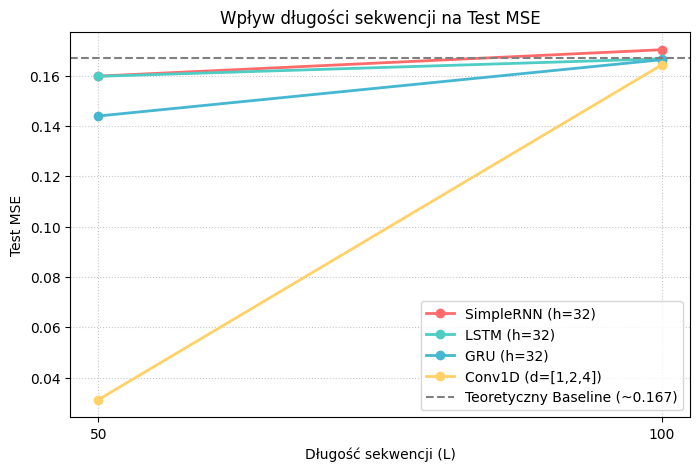

In [6]:
plt.figure(figsize=(8, 5))
modele_podstawowe = ['SimpleRNN (h=32)', 'LSTM (h=32)', 'GRU (h=32)', 'Conv1D (d=[1,2,4])']
kolory = ['#ff6b6b', '#4ecdc4', '#45b7d1', '#ffd166']

for i, m_name in enumerate(modele_podstawowe):
    mse_vals = [wyniki[50][m_name]['mse'], wyniki[100][m_name]['mse']]
    plt.plot([50, 100], mse_vals, marker='o', label=m_name, color=kolory[i], linewidth=2)

plt.axhline(0.167, ls='--', color='gray', label='Teoretyczny Baseline (~0.167)')
plt.xticks([50, 100])
plt.xlabel('Długość sekwencji (L)')
plt.ylabel('Test MSE')
plt.title('Wpływ długości sekwencji na Test MSE')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()